# TP2 — Préparation et qualité des sources (Online Retail · Kaggle)
**M115 · Analyse de Données Multidimensionnelles et BI — ENSAB** · Pr. Amina ABOULMIRA
Binôme / notebook Kaggle : `tp2-bi-mouhib-wissal-loubna-sadik-Najat ztoti`

> **Protocole suivi** : fiche *« Préparation au TP2 avec Kaggle »* — chaîne commune du fichier brut à **L2**, **noms de DataFrames imposés**, code de la fiche **exécuté tel quel**. Chaque phase suit l'ordre **Objectif → Code → Observation → Preuve** : l'explication du code, le code de la fiche, puis les tableaux de relevés **remplis avec les valeurs réellement obtenues**, une interprétation, et un graphique facultatif.

### La chaîne commune
| Phase | Étape | Idée |
|---|---|---|
| 01 | Staging brut | copier et repérer les lignes (`SourceIndex`, `SourceRow`) |
| 02 | Audit initial | observer **sans supprimer** |
| 03 | Dédoublonnage | retirer **uniquement** les copies exactes (8 colonnes) |
| 04 | Normalisation | dériver et vérifier les types (colonnes `_norm`, `_num`, `_dt`) |
| 05 | Intégration | appliquer le référentiel commun (`TypeLigne`) |
| 06 | Sélection | tracer les motifs d'exclusion sans les additionner deux fois |
| 07 | Contrôle (journal) | filtres successifs `etape_0` → `etape_4` |
| 08 | Contrôle final | réconcilier lignes, provenances et montants |
| 09 | Livraison L2 | exporter les CSV + rapport HTML |

### Contrat des DataFrames (noms à respecter)
| Nom | Contenu |
|---|---|
| `brut` | données originales + métadonnées ; **jamais modifié ensuite** |
| `doublons_exacts` | occurrences supplémentaires identiques sur les huit colonnes |
| `staging_unique` | premières occurrences conservées |
| `staging_type` | champs originaux + colonnes dérivées typées/normalisées |
| `integration` | staging enrichi de `TypeLigne`, des règles et des motifs |
| `etape_0` … `etape_4` | états successifs du filtrage, dans l'ordre imposé |
| `preparee` | ventes admissibles et `MontantLigne` |
| `audit_exclusions` | lignes uniques non admissibles, conservées pour audit |
| `journal` / `controle_final` | tableaux calculés à reporter et à commenter |

**Comment l'utiliser sur Kaggle** : créer un Notebook Python → **Add Data** → ajouter `Online Retail.xlsx` (un seul fichier) → **Run All**. Si vous obtenez un chiffre différent de ceux de ce notebook, voir la section « Quand deux montants finaux diffèrent » à la fin.

---
## PHASE 01 · Kaggle et staging brut
### Objectif
Obtenir une **copie fidèle, sans retrait**, du fichier source et noter son **empreinte SHA-256** : si deux binômes ont des empreintes différentes, ils n'ont pas la même version du fichier, et il est inutile de comparer la suite.

### Explication du code
- `colonnes_source` : le **contrat des huit colonnes** attendues.
- `Path("/kaggle/input").rglob("Online Retail.xlsx")` : cherche le fichier dans les données Kaggle ; `assert len(fichiers) == 1` s'arrête s'il y en a 0 ou plusieurs (même version pour tout le monde).
- `pd.read_excel(source)` : charge le classeur dans le DataFrame `brut` ; l'`assert list(brut.columns) == colonnes_source` vérifie le contrat des colonnes **et leur ordre**.
- `SourceIndex` : index initial **commençant à zéro** (`np.arange`). `SourceRow` : n° de ligne **dans Excel** (`+ 2` car la ligne 1 est l'en-tête). `SourceFile` : nom du fichier. Ce sont des **métadonnées de traçabilité**, pas des clés métier.
- `hashlib.sha256(source.read_bytes()).hexdigest()` : empreinte du **contenu** du fichier.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import html
import hashlib

colonnes_source = [
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "Country"
]
fichiers = sorted(Path("/kaggle/input").rglob("Online Retail.xlsx"))
assert len(fichiers) == 1, "Ajouter un seul fichier Online Retail.xlsx dans les données Kaggle."
source = fichiers[0]
sortie = Path("/kaggle/working")
sortie.mkdir(parents=True, exist_ok=True)
brut = pd.read_excel(source)
assert list(brut.columns) == colonnes_source, "Vérifier le contrat des huit colonnes."
brut["SourceIndex"] = np.arange(len(brut))
brut["SourceRow"] = brut["SourceIndex"] + 2
brut["SourceFile"] = source.name
empreinte = hashlib.sha256(source.read_bytes()).hexdigest()
print("Empreinte du fichier :", empreinte)
print("Lignes :", len(brut), "Colonnes métier :", len(colonnes_source))
print(brut[colonnes_source + ["SourceIndex", "SourceRow"]].head().to_string(index=False))

Empreinte du fichier : 43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d
Lignes : 541909 Colonnes métier : 8
InvoiceNo StockCode                         Description  Quantity         InvoiceDate  UnitPrice  CustomerID        Country  SourceIndex  SourceRow
   536365    85123A  WHITE HANGING HEART T-LIGHT HOLDER         6 2010-12-01 08:26:00       2.55     17850.0 United Kingdom            0          2
   536365     71053                 WHITE METAL LANTERN         6 2010-12-01 08:26:00       3.39     17850.0 United Kingdom            1          3
   536365    84406B      CREAM CUPID HEARTS COAT HANGER         8 2010-12-01 08:26:00       2.75     17850.0 United Kingdom            2          4
   536365    84029G KNITTED UNION FLAG HOT WATER BOTTLE         6 2010-12-01 08:26:00       3.39     17850.0 United Kingdom            3          5
   536365    84029E      RED WOOLLY HOTTIE WHITE HEART.         6 2010-12-01 08:26:00       3.39     17850.0 United Kingdom            4

### Observation — tableau à relever
| Information à relever | Votre observation |
|---|---|
| Binôme / notebook Kaggle | `tp2-bi-mouhib-wissal-loubna-sadik` |
| Fichier et empreinte SHA-256 | `Online Retail.xlsx` — `43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d` |
| Nombre de lignes brutes | **541 909** |
| Nombre de colonnes métier | **8** (`InvoiceNo`, `StockCode`, `Description`, `Quantity`, `InvoiceDate`, `UnitPrice`, `CustomerID`, `Country`) |

**Interprétation.** La copie est fidèle : 541 909 lignes, 8 colonnes, `SourceIndex` de 0 à 541 908, `SourceRow` de 2 à 541 910. L'empreinte ci-dessus est celle du fichier utilisé pour ce notebook : **comparez-la avec celle affichée par votre propre exécution** (c'est exactement la vérification demandée par la consigne).

### Outils graphiques (facultatif)
Cette cellule ne fait **partie ni du protocole ni du contrat** : elle prépare seulement le style des graphes facultatifs placés après chaque phase. Elle ne modifie aucun DataFrame.

In [2]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 12, 'font.size': 10})
C_PRIM, C_BLEU, C_ROUGE, C_ORANGE, C_VERT, C_GRIS = '#3b4a8a', '#4aa3c7', '#c0392b', '#d68910', '#2e8b6f', '#9aa3b2'

def fr(x, d=0):
    """Format français : 1234567.8 -> '1 234 568'."""
    return f"{x:,.{d}f}".replace(',', ' ').replace('.', ',')

---
## PHASE 02 · Audit initial : observer, sans filtrer
### Objectif
Mesurer l'état de la source **avant toute décision** : types, valeurs manquantes, annulations, copies exactes. Ces observations **ne sont pas encore des décisions d'exclusion** (par exemple, un `CustomerID` absent ne justifie pas de retirer une vente admissible). **Aucun `dropna()` global n'est autorisé.**

### Explication du code
- `audit_initial` : un DataFrame construit colonne par colonne avec une *compréhension de liste* : `brut[c].dtype` donne le type, `brut[c].isna().sum()` compte les valeurs manquantes (`isna()` → masque True/False, `sum()` → nombre de True).
- `brut["InvoiceNo"].astype(str).str.startswith("C").sum()` : nombre de numéros de facture commençant par `C` (`astype(str)` car la colonne mélange entiers et textes).
- `brut.duplicated(subset=colonnes_source, keep="first").sum()` : nombre de **copies supplémentaires** (lignes identiques sur les 8 colonnes à une ligne plus haut ; la première occurrence n'est pas comptée). Les métadonnées `Source…` sont exclues du `subset`, sinon aucune ligne ne serait jamais identique.

In [3]:
audit_initial = pd.DataFrame({
    "Colonne": colonnes_source,
    "Type_observe": [str(brut[c].dtype) for c in colonnes_source],
    "Valeurs_manquantes": [int(brut[c].isna().sum()) for c in colonnes_source]
})
print(audit_initial.to_string(index=False))
print("Commandes commençant par C :",
      brut["InvoiceNo"].astype(str).str.startswith("C").sum())
print("Copies exactes supplémentaires :",
      brut.duplicated(subset=colonnes_source, keep="first").sum())

    Colonne   Type_observe  Valeurs_manquantes
  InvoiceNo         object                   0
  StockCode         object                   0
Description         object                1454
   Quantity          int64                   0
InvoiceDate datetime64[us]                   0
  UnitPrice        float64                   0
 CustomerID        float64              135080
    Country            str                   0
Commandes commençant par C : 9288


Copies exactes supplémentaires : 5268


### Observation — tableau à relever
| Colonne | Type observé | Valeurs manquantes |
|---|---|---|
| InvoiceNo | `object` (mélange de nombres et de textes comme `C536379`) | 0 |
| StockCode | `object` | 0 |
| Description | `object` | **1 454** |
| Quantity | `int64` | 0 |
| InvoiceDate | `datetime64` (`[ns]` ou `[us]` selon la version de pandas) | 0 |
| UnitPrice | `float64` | 0 |
| CustomerID | `float64` (décimal à cause des valeurs manquantes) | **135 080** |
| Country | `object` (affiché `str` avec pandas ≥ 3) | 0 |

Autres relevés : **9 288** commandes commençant par `C` ; **5 268** copies exactes supplémentaires.

**Interprétation et anomalie éventuelle.** Seules deux colonnes ont des manquants : `CustomerID` (24,9 % des lignes) et `Description` (0,27 %). Le type du type observé dépend de la version de pandas (`object`/`str`, `ns`/`us`) : ce n'est pas une anomalie. `CustomerID` est décimal (`17850.0`) uniquement parce que les NaN empêchent un entier classique : on s'en souviendra en phase 04. Les 9 288 factures `C` et les 5 268 copies sont **observées, pas encore retirées**.

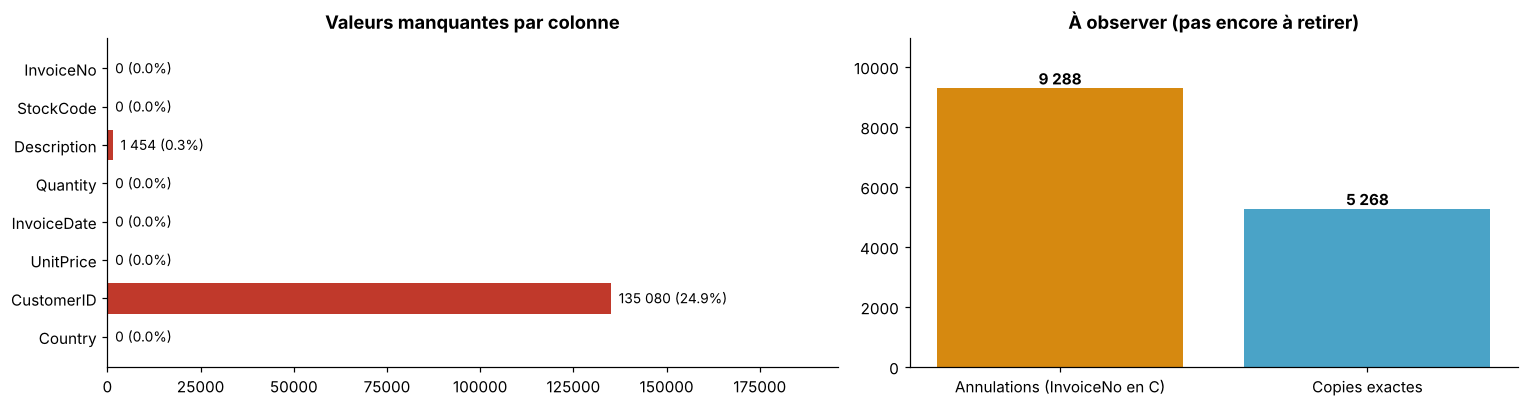

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={'width_ratios': [1.2, 1]})
m = audit_initial.set_index('Colonne')['Valeurs_manquantes']
axes[0].barh(m.index[::-1], m.values[::-1], color=[C_ROUGE if v > 0 else C_GRIS for v in m.values[::-1]])
for i, v in enumerate(m.values[::-1]):
    axes[0].text(v, i, f'  {fr(v)} ({v/len(brut):.1%})', va='center', fontsize=9)
axes[0].set_xlim(0, m.max() * 1.45); axes[0].set_title('Valeurs manquantes par colonne')

obs = pd.Series({'Annulations (InvoiceNo en C)': int(brut['InvoiceNo'].astype(str).str.startswith('C').sum()),
                 'Copies exactes': int(brut.duplicated(subset=colonnes_source).sum())})
axes[1].bar(obs.index, obs.values, color=[C_ORANGE, C_BLEU])
for i, v in enumerate(obs.values):
    axes[1].text(i, v, fr(v), ha='center', va='bottom', fontweight='bold')
axes[1].set_ylim(0, obs.max() * 1.18); axes[1].set_title('À observer (pas encore à retirer)')
plt.tight_layout(); plt.show()

**Lecture du graphe.** `CustomerID` domine largement les manquants (rouge) ; les autres colonnes sont complètes. Les annulations et les copies exactes sont des volumes du même ordre de grandeur (≈ 1–2 % des lignes) mais de **nature différente** : une copie est une erreur technique, une annulation est un événement métier.

---
## PHASE 03 · Staging dédoublonné : uniquement les copies exactes
### Objectif
Retirer **uniquement** les copies strictement identiques sur les huit colonnes d'origine, en gardant la **première occurrence**, et **conserver** les copies retirées dans `doublons_exacts` (elles ne seront pas recomptées dans `audit_exclusions`).

### Explication du code
- `masque_doublon = brut.duplicated(..., keep="first")` : masque booléen, **True = copie supplémentaire**.
- `brut.loc[masque_doublon].copy()` → `doublons_exacts` ; `brut.loc[~masque_doublon].copy()` → `staging_unique` (`~` inverse le masque ; `.copy()` crée un tableau de travail indépendant).
- Les deux `assert` prouvent que **rien n'est perdu** (`brut = copies + uniques`) et qu'**il ne reste plus de doublon exact**.
- La comparaison porte sur les huit colonnes **avant toute normalisation**.

> ⚠️ **Ne jamais utiliser seulement `InvoiceNo + StockCode`** : deux lignes du même produit dans une commande peuvent être légitimes (quantités ou prix différents).

In [5]:
masque_doublon = brut.duplicated(subset=colonnes_source, keep="first")
doublons_exacts = brut.loc[masque_doublon].copy()
staging_unique = brut.loc[~masque_doublon].copy()
assert len(brut) == len(doublons_exacts) + len(staging_unique)
assert not staging_unique.duplicated(subset=colonnes_source).any()
print("Copies retirées :", len(doublons_exacts))
print("Lignes uniques :", len(staging_unique))
print(doublons_exacts[["SourceIndex", "InvoiceNo", "StockCode", "Quantity"]].head().to_string(index=False))

Copies retirées : 5268
Lignes uniques : 536641
 SourceIndex InvoiceNo StockCode  Quantity
         517    536409     21866         1
         527    536409     22866         1
         537    536409     22900         1
         539    536409     22111         1
         555    536412     22327         1


### Observation — tableau à relever
| Contrôle | Valeur mesurée |
|---|---|
| Copies exactes retirées | **5 268** |
| Lignes uniques restantes | **536 641** |
| Réconciliation brut = copies + uniques | **541 909 = 5 268 + 536 641** ✅ (assert réussi) |

**Interprétation.** Les 5 268 copies (≈ 0,97 %) sont conservées dans `doublons_exacts` avec leur `SourceIndex` (par exemple la copie `SourceIndex = 517`, facture 536409, article 21866). Le contrôle de réconciliation est exact. Le nombre de copies est identique à celui mesuré en phase 02 : le dédoublonnage ne fait que **matérialiser** ce que l'audit avait observé.

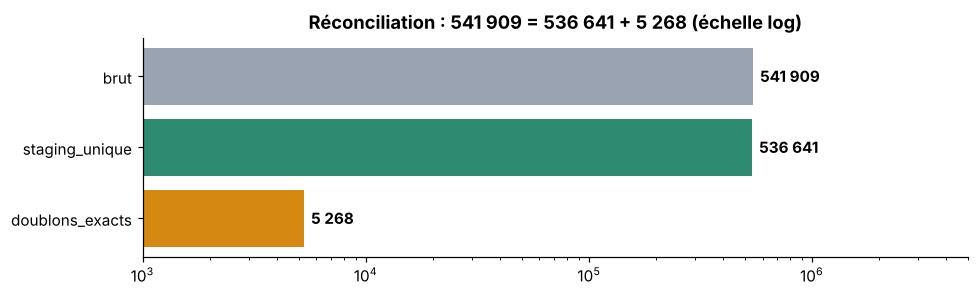

In [6]:
fig, ax = plt.subplots(figsize=(9, 2.8))
vals = pd.Series({'brut': len(brut), 'staging_unique': len(staging_unique), 'doublons_exacts': len(doublons_exacts)})
ax.barh(vals.index[::-1], vals.values[::-1], color=[C_ORANGE, C_VERT, C_GRIS])
for i, v in enumerate(vals.values[::-1]):
    ax.text(v, i, f'  {fr(v)}', va='center', fontweight='bold')
ax.set_xscale('log'); ax.set_xlim(1e3, 5e6)
ax.set_title(f'Réconciliation : {fr(len(brut))} = {fr(len(staging_unique))} + {fr(len(doublons_exacts))} (échelle log)')
plt.tight_layout(); plt.show()

**Lecture.** Les lignes uniques (vert) et les copies exactes (gris) reconstituent exactement le brut (orange) : 536 641 + 5 268 = 541 909. L'échelle est logarithmique pour que les 5 268 copies restent visibles à côté des 536 641 lignes uniques.

---
## PHASE 04 · Normalisation, typage et traçabilité
### Objectif
Créer des colonnes **dérivées** propres et typées **sans toucher aux champs originaux**. Convention client : une absence ou une chaîne vide (après retrait des espaces) signifie **« identifiant absent »**. Aucun client technique n'est créé en TP2.

### Explication du code
- `staging_type = staging_unique.copy()` : on part des lignes uniques.
- Pour `StockCode`, `Description`, `Country` : `.astype("string").str.strip().str.upper()` → colonnes `_norm` (texte, sans espaces aux extrémités, en majuscules : harmonise les comparaisons). `InvoiceNo_norm` : seulement `strip()` (pas de `upper()`).
- `CustomerID_norm` : converti en texte, `strip()`, puis `replace("", pd.NA)` : une chaîne vide devient « absent ».
- `Quantity_num` / `UnitPrice_num` : `pd.to_numeric(..., errors="coerce")` convertit en nombres ; une valeur **non convertible** devient `NaN` au lieu de provoquer une erreur. `_echec` = « valeur d'origine présente **ET** conversion absente » : ça distingue une **conversion échouée** d'une **absence initiale**.
- `InvoiceDate_dt` : si la colonne est déjà de type date (cas du classeur Excel), conversion directe ; sinon, format explicite **jour/mois/année**.
- `anomalies_typage` : les lignes où une conversion a échoué. Les deux `assert` finaux exigent **aucune anomalie** : sinon on **montre** les anomalies à l'enseignante au lieu d'inventer un filtre.
- `errors="coerce"` ne corrige pas et **ne supprime pas** la ligne.

In [7]:
staging_type = staging_unique.copy()
for c in ["StockCode", "Description", "Country"]:
    staging_type[c + "_norm"] = staging_type[c].astype("string").str.strip().str.upper()
staging_type["InvoiceNo_norm"] = staging_type["InvoiceNo"].astype("string").str.strip()
staging_type["CustomerID_norm"] = (
    staging_type["CustomerID"].astype("string").str.strip().replace("", pd.NA)
)
for c in ["Quantity", "UnitPrice"]:
    staging_type[c + "_num"] = pd.to_numeric(staging_type[c], errors="coerce")
    staging_type[c + "_echec"] = (
        staging_type[c].notna() & staging_type[c + "_num"].isna()
    )
# Le classeur fourni contient des dates Excel reconnues par read_excel.
if pd.api.types.is_datetime64_any_dtype(staging_type["InvoiceDate"]):
    staging_type["InvoiceDate_dt"] = pd.to_datetime(staging_type["InvoiceDate"], errors="coerce")
else:
    # Pour une source textuelle : convention explicite jour/mois/année.
    staging_type["InvoiceDate_dt"] = pd.to_datetime(
        staging_type["InvoiceDate"], format="%d/%m/%Y %H:%M", errors="coerce"
    )
staging_type["InvoiceDate_echec"] = (
    staging_type["InvoiceDate"].notna() & staging_type["InvoiceDate_dt"].isna()
)
anomalies_typage = staging_type.loc[
    staging_type[["Quantity_echec", "UnitPrice_echec", "InvoiceDate_echec"]].any(axis=1)
    | staging_type["Quantity_num"].isna()
    | staging_type["UnitPrice_num"].isna()
    | staging_type["InvoiceDate_dt"].isna()
].copy()
print(staging_type[["StockCode", "StockCode_norm", "Quantity", "Quantity_num"]].head().to_string(index=False))
print("Anomalies à diagnostiquer :", len(anomalies_typage))
assert len(staging_type) == len(staging_unique)
assert anomalies_typage.empty, "Ne pas inventer un filtre : montrer les anomalies à l'enseignante."

StockCode StockCode_norm  Quantity  Quantity_num
   85123A         85123A         6             6
    71053          71053         6             6
   84406B         84406B         8             8
   84029G         84029G         6             6
   84029E         84029E         6             6
Anomalies à diagnostiquer : 0


### Observation
| Contrôle | Résultat |
|---|---|
| Lignes de `staging_type` | **536 641** (= `staging_unique`) |
| `Quantity_echec`, `UnitPrice_echec`, `InvoiceDate_echec` | 0 échec de conversion |
| `anomalies_typage` | **0** ligne ✅ (les deux `assert` passent) |

**Interprétation.** Toutes les quantités, tous les prix et toutes les dates sont convertibles : il n'y a **aucune anomalie de typage** à signaler. Les champs originaux (`StockCode`, `Quantity`…) sont intacts à côté de leurs versions dérivées (`StockCode_norm`, `Quantity_num`…). Point à retenir pour TP3 : `CustomerID_norm` vaut par exemple `"17850.0"` (texte avec `.0`) parce que la colonne d'origine est décimale ; la fiche demande de relire les identifiants **en texte** avant de les utiliser comme clés.

---
## PHASE 05 · Intégration : appliquer le référentiel commun
### Objectif
Appliquer **exactement le même dictionnaire** et la même règle de description pour tous les binômes. La classification est une **règle commune de la démonstration, pas une règle universelle** : un code absent du dictionnaire n'est pas une preuve métier en soi.

### Explication du code
- `codes_non_commerciaux` : dictionnaire *code → type* (`POST`/`DOT`/`C2` = `FRAIS_PORT`, `M`/`B`/`PADS` = `AJUSTEMENT`, `D` = `REMISE`, `BANK CHARGES` = `FRAIS_BANCAIRES`, `AMAZONFEE`/`CRUK` = `COMMISSION`, `S` = `ECHANTILLON`, `GIFT_0001_xx` = `BON_CADEAU`). Les codes sont comparés **après `upper()`**, d'où `GIFT_…` en majuscules.
- `code.map(codes_non_commerciaux)` : cherche chaque code dans le dictionnaire ; `.fillna("PRODUIT_COMMERCIAL")` : **règle par défaut** pour tout code absent.
- `OrigineClassification` (`np.where`) : `REFERENTIEL_CODE` si le code est dans le dictionnaire, sinon `REGLE_PAR_DEFAUT` (**traçabilité** de la règle).
- `motif` : expression régulière de **mots suspects** dans la description (`ADJUSTMENT`, `POSTAGE`, `SAMPLES?`, `CARRIAGE`…). `suspect & TypeLigne == "PRODUIT_COMMERCIAL"` → ces lignes passent en **`A_VERIFIER`** (origine `DESCRIPTION_SUSPECTE`) : identifiables et **hors des ventes retenues** tant qu'aucune décision commune ne les a résolues.
- `classification_effectifs` : `value_counts()` des types ; deux `assert` vérifient qu'aucune ligne n'a disparu.

> La lettre **A** de `85123A` ne justifie **aucune** exclusion : c'est une variante de produit.

In [8]:
codes_non_commerciaux = {
    "POST": "FRAIS_PORT", "DOT": "FRAIS_PORT", "C2": "FRAIS_PORT",
    "M": "AJUSTEMENT", "B": "AJUSTEMENT", "PADS": "AJUSTEMENT",
    "D": "REMISE", "BANK CHARGES": "FRAIS_BANCAIRES",
    "AMAZONFEE": "COMMISSION", "CRUK": "COMMISSION",
    "S": "ECHANTILLON",
    "GIFT_0001_10": "BON_CADEAU", "GIFT_0001_20": "BON_CADEAU",
    "GIFT_0001_30": "BON_CADEAU", "GIFT_0001_40": "BON_CADEAU",
    "GIFT_0001_50": "BON_CADEAU"
}
integration = staging_type.copy()
code = integration["StockCode_norm"].fillna("")
description = integration["Description_norm"].fillna("")
integration["TypeLigne"] = code.map(codes_non_commerciaux).fillna("PRODUIT_COMMERCIAL")
integration["OrigineClassification"] = np.where(
    code.isin(codes_non_commerciaux), "REFERENTIEL_CODE", "REGLE_PAR_DEFAUT"
)
motif = (
    r"\b(?:ADJUSTMENT|MANUAL|POSTAGE|BANK CHARGES|AMAZON FEE|"
    r"DISCOUNT|SAMPLES?|COMMISSION|CARRIAGE|DOTCOM POSTAGE)\b"
)
suspect = description.str.contains(motif, regex=True, na=False)
a_verifier = suspect & integration["TypeLigne"].eq("PRODUIT_COMMERCIAL")
integration.loc[a_verifier, "TypeLigne"] = "A_VERIFIER"
integration.loc[a_verifier, "OrigineClassification"] = "DESCRIPTION_SUSPECTE"
classification_effectifs = integration["TypeLigne"].value_counts().rename_axis("TypeLigne").reset_index(name="Nombre")
assert len(integration) == len(staging_type)
assert classification_effectifs["Nombre"].sum() == len(integration)
print(classification_effectifs.to_string(index=False))
print(integration[["SourceIndex", "StockCode", "Description", "TypeLigne", "OrigineClassification"]].head().to_string(index=False))

         TypeLigne  Nombre
PRODUIT_COMMERCIAL  533490
        FRAIS_PORT    2110
        AJUSTEMENT     574
        A_VERIFIER     207
            REMISE      77
       ECHANTILLON      62
        COMMISSION      50
   FRAIS_BANCAIRES      37
        BON_CADEAU      34
 SourceIndex StockCode                         Description          TypeLigne OrigineClassification
           0    85123A  WHITE HANGING HEART T-LIGHT HOLDER PRODUIT_COMMERCIAL      REGLE_PAR_DEFAUT
           1     71053                 WHITE METAL LANTERN PRODUIT_COMMERCIAL      REGLE_PAR_DEFAUT
           2    84406B      CREAM CUPID HEARTS COAT HANGER PRODUIT_COMMERCIAL      REGLE_PAR_DEFAUT
           3    84029G KNITTED UNION FLAG HOT WATER BOTTLE PRODUIT_COMMERCIAL      REGLE_PAR_DEFAUT
           4    84029E      RED WOOLLY HOTTIE WHITE HEART. PRODUIT_COMMERCIAL      REGLE_PAR_DEFAUT


### Observation — tableau à relever
| Classification | Effectif mesuré |
|---|---|
| PRODUIT_COMMERCIAL | **533 490** |
| FRAIS_PORT | **2 110** |
| AJUSTEMENT | **574** |
| REMISE | **77** |
| FRAIS_BANCAIRES | **37** |
| COMMISSION | **50** |
| ECHANTILLON | **62** |
| BON_CADEAU | **34** |
| A_VERIFIER | **207** |
| **TOTAL** | **536 641** (= `len(integration)` ✅) |

**Interprétation et anomalie éventuelle.**
- 99,4 % des lignes sont des produits commerciaux. `AJUSTEMENT` = `M` (567), `PADS` (4), `B` (3).
- Les **207 `A_VERIFIER`** viennent de la description, pas du code : `NEXT DAY CARRIAGE` (80), `FRENCH CARRIAGE LANTERN` (63), `BLACK BAROQUE CARRIAGE CLOCK` (35), `ADJUSTMENT` (18), quelques libellés `SAMPLES…`, etc.
- ⚠️ **Cas non résolu à documenter** : le motif `CARRIAGE` attrape aussi de **vrais produits** (*French carriage lantern*, *Black baroque carriage clock*). La règle commune les place en `A_VERIFIER` : ils sont donc exclus des ventes alors qu'ils semblent légitimes. On **ne modifie pas la règle** (consigne : le référentiel est commun et doit être validé) ; on **signale** le cas à l'enseignante. Parmi les **173** `A_VERIFIER` qui seraient admissibles par ailleurs (non annulées, quantité > 0, prix > 0 ; montant **2 558,14**), **94** (montant **1 358,14**) sont de vrais produits (*lantern*, *clock*) et **79** (montant **1 200,00**) sont de vrais frais de livraison (`NEXT DAY CARRIAGE`). Voir la cellule d'analyse juste après.
- Les codes `DCGS…` (cadeaux, `DCGSSGIRL`, `DCGSSBOY`…) ne sont **pas** dans le dictionnaire : ils restent `PRODUIT_COMMERCIAL` par la règle par défaut.

In [9]:
# Analyse complémentaire (hors protocole) : les A_VERIFIER qui auraient été admissibles par ailleurs
av = integration[integration["TypeLigne"].eq("A_VERIFIER")]
av_admissibles = av[(~av["Annulation"]) & (av["Quantity_num"] > 0) & (av["UnitPrice_num"] > 0)] if "Annulation" in av else None
if av_admissibles is None:
    # Annulation est créée en phase 06 : on la recalcule ici sans toucher à integration
    est_annule = av["InvoiceNo_norm"].str.startswith("C", na=False)
    av_admissibles = av[(~est_annule) & (av["Quantity_num"] > 0) & (av["UnitPrice_num"] > 0)]
print("A_VERIFIER :", len(av), "| dont admissibles par ailleurs (non annulées, Q>0, P>0) :", len(av_admissibles),
      "| montant :", round((av_admissibles["Quantity_num"] * av_admissibles["UnitPrice_num"]).sum(), 2))
print(av_admissibles["Description_norm"].value_counts().head(8).to_string())

A_VERIFIER : 207 | dont admissibles par ailleurs (non annulées, Q>0, P>0) : 173 | montant : 2558.14
Description_norm
NEXT DAY CARRIAGE               79
FRENCH CARRIAGE LANTERN         59
BLACK BAROQUE CARRIAGE CLOCK    35


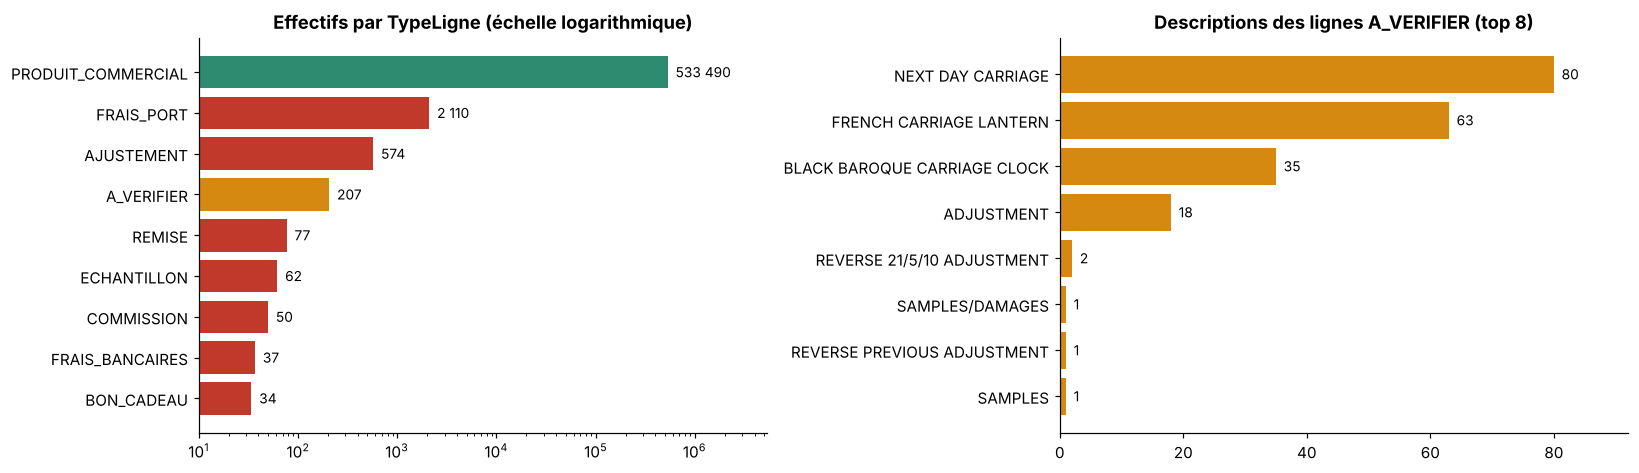

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
ordre = classification_effectifs.sort_values('Nombre')
cols = [C_VERT if t == 'PRODUIT_COMMERCIAL' else C_ORANGE if t == 'A_VERIFIER' else C_ROUGE for t in ordre['TypeLigne']]
axes[0].barh(ordre['TypeLigne'], ordre['Nombre'], color=cols); axes[0].set_xscale('log')
for i, v in enumerate(ordre['Nombre']):
    axes[0].text(v, i, f'  {fr(v)}', va='center', fontsize=9)
axes[0].set_xlim(10, ordre['Nombre'].max() * 10)
axes[0].set_title('Effectifs par TypeLigne (échelle logarithmique)')

top = av['Description_norm'].value_counts().head(8).sort_values()
axes[1].barh(top.index, top.values, color=C_ORANGE)
for i, v in enumerate(top.values):
    axes[1].text(v, i, f'  {v}', va='center', fontsize=9)
axes[1].set_xlim(0, top.max() * 1.15); axes[1].set_title('Descriptions des lignes A_VERIFIER (top 8)')
plt.tight_layout(); plt.show()

**Lecture.** À gauche : les produits commerciaux écrasent tout le reste (l'échelle logarithmique rend les petites classes visibles). À droite : ce qui déclenche `A_VERIFIER`. Trois libellés contenant `CARRIAGE` pèsent presque autant que tout le reste : `NEXT DAY CARRIAGE` est bien un frais de livraison, mais *lantern* et *clock* sont des produits → **cas à faire trancher**, car le motif ne distingue pas le sens du mot.

---
## PHASE 06 · Motifs : expliquer les exclusions sans les additionner deux fois
### Objectif
Poser, pour chaque ligne, **tous** les motifs qui l'excluent, et un indicateur `InclureFactVente` = « admissible pour la future table de ventes ». **Aucune table de faits n'est construite ici.**

### Explication du code
- Un **masque** est une série de True/False ; `&` = « et », `|` = « ou », `~` = « non » ; chaque condition composée est entre parenthèses.
- `Annulation` : `InvoiceNo_norm` commence par `C` (`na=False` : un manquant n'est pas une annulation).
- `flags` : quatre indicateurs : `ANNULATION`, `QUANTITE_NON_POSITIVE` (`le(0)` = « ≤ 0 »), `PRIX_NON_POSITIF`, `TYPE_HORS_VENTES` (`ne("PRODUIT_COMMERCIAL")` = « différent de »).
- La boucle `for nom in flags.columns` **concatène** les noms des indicateurs vrais dans `MotifsExclusion` (séparés par `;`, le dernier `;` est retiré par `rstrip`).
- `InclureFactVente = ~flags.any(axis=1)` : vrai si **aucun** motif ne s'applique.
- Un type commercial autorisé **ne suffit pas** : la vente doit aussi satisfaire quantité, prix et annulation.

In [11]:
integration["Annulation"] = integration["InvoiceNo_norm"].str.startswith("C", na=False)
flags = pd.DataFrame({
    "ANNULATION": integration["Annulation"],
    "QUANTITE_NON_POSITIVE": integration["Quantity_num"].le(0),
    "PRIX_NON_POSITIF": integration["UnitPrice_num"].le(0),
    "TYPE_HORS_VENTES": integration["TypeLigne"].ne("PRODUIT_COMMERCIAL")
}, index=integration.index)
# Pour chaque ligne, recueillir les noms des indicateurs vrais.
integration["MotifsExclusion"] = ""
for nom in flags.columns:
    positions = flags[nom]
    integration.loc[positions, "MotifsExclusion"] += nom + ";"
integration["MotifsExclusion"] = integration["MotifsExclusion"].str.rstrip(";")
integration["InclureFactVente"] = ~flags.any(axis=1)
print(integration[["SourceIndex", "TypeLigne", "InclureFactVente", "MotifsExclusion"]].head(12).to_string(index=False))
print("Effectifs par motif (chevauchements possibles) :")
print(flags.sum().to_string())

 SourceIndex          TypeLigne  InclureFactVente MotifsExclusion
           0 PRODUIT_COMMERCIAL              True                
           1 PRODUIT_COMMERCIAL              True                
           2 PRODUIT_COMMERCIAL              True                
           3 PRODUIT_COMMERCIAL              True                
           4 PRODUIT_COMMERCIAL              True                
           5 PRODUIT_COMMERCIAL              True                
           6 PRODUIT_COMMERCIAL              True                
           7 PRODUIT_COMMERCIAL              True                
           8 PRODUIT_COMMERCIAL              True                
           9 PRODUIT_COMMERCIAL              True                
          10 PRODUIT_COMMERCIAL              True                
          11 PRODUIT_COMMERCIAL              True                
Effectifs par motif (chevauchements possibles) :
ANNULATION                9251
QUANTITE_NON_POSITIVE    10587
PRIX_NON_POSITIF          2512


### Observation
| Motif | Effectif (chevauchements possibles) |
|---|---|
| ANNULATION | **9 251** |
| QUANTITE_NON_POSITIVE | **10 587** |
| PRIX_NON_POSITIF | **2 512** |
| TYPE_HORS_VENTES | **3 151** |

Les 12 premières lignes sont toutes `PRODUIT_COMMERCIAL` admissibles (`InclureFactVente = True`, `MotifsExclusion` vide).

**Interprétation.** La somme des motifs (9 251 + 10 587 + 2 512 + 3 151 = **25 501**) est **supérieure** au nombre de lignes exclues (**14 277**) parce que **les motifs se chevauchent** : par exemple une annulation a presque toujours aussi une quantité négative (« deux motifs, une seule ligne »). Le détail des combinaisons est dans le graphe suivant : **les effectifs par motif ne sont donc pas une partition** et ne doivent jamais être additionnés.

Lignes exclues : 14 277 | Σ des effectifs par motif : 25 501


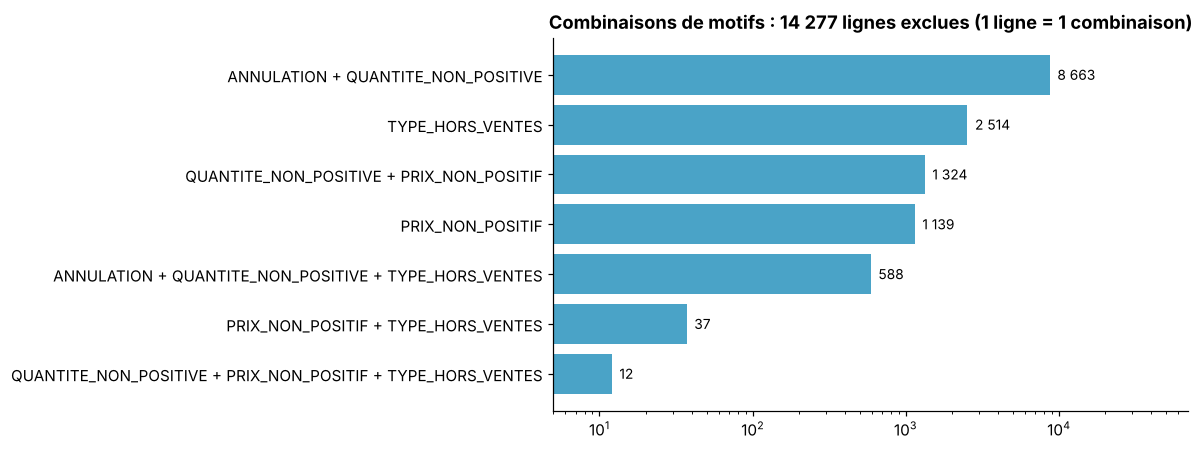

In [12]:
combi = integration.loc[~integration['InclureFactVente'], 'MotifsExclusion'].value_counts()
print('Lignes exclues :', fr(combi.sum()), '| Σ des effectifs par motif :', fr(int(flags.sum().sum())))
fig, ax = plt.subplots(figsize=(11, 4.2))
c = combi.sort_values()
ax.barh(c.index.str.replace(';', ' + '), c.values, color=C_BLEU)
for i, v in enumerate(c.values):
    ax.text(v, i, f'  {fr(v)}', va='center', fontsize=9)
ax.set_xscale('log'); ax.set_xlim(5, c.max() * 8)
ax.set_title(f'Combinaisons de motifs : {fr(combi.sum())} lignes exclues (1 ligne = 1 combinaison)')
plt.tight_layout(); plt.show()

**Lecture.** Chaque ligne exclue apparaît dans **une seule barre** : c'est la vraie partition. Les deux plus grosses combinaisons sont `ANNULATION + QUANTITE_NON_POSITIVE` (retours) et `TYPE_HORS_VENTES` seul (frais, commissions… à prix et quantité positifs).

---
## PHASE 07 · Filtres successifs : remplir le journal de comparaison
### Objectif
Appliquer les filtres **dans l'ordre imposé** avec les **noms imposés** (`etape_0` à `etape_4`). Chaque retrait est compté **par rapport à l'étape précédente**. La somme intermédiaire est **signée** : enlever des lignes négatives peut **faire augmenter** le montant. Les étapes avant la sélection finale ne sont pas encore des ventes MVP.

### Explication du code
- `etape_0` = `integration` ; `etape_1` = sans annulations ; `etape_2` = `Quantity_num > 0` (`.gt(0)`) ; `etape_3` = `UnitPrice_num > 0` ; `etape_4` = `TypeLigne == PRODUIT_COMMERCIAL` (`.eq(...)`). Chaque étape part de la précédente.
- `montant(df)` : Σ `Quantity_num × UnitPrice_num`.
- `journal` : une ligne par étape : condition conservée, lignes retirées (`len(étape précédente) − len(étape courante)`), restantes, quantité totale, montant, clients absents.
- `preparee` = `etape_4` + `MontantLigne` (colonne **dérivée**) ; `audit_exclusions` = toutes les lignes de `integration` avec `InclureFactVente == False`.
- Le dernier `assert` prouve que `preparee` correspond exactement à `InclureFactVente == True`.

In [13]:
etape_0 = integration.copy()
etape_1 = etape_0.loc[~etape_0["Annulation"]].copy()
etape_2 = etape_1.loc[etape_1["Quantity_num"].gt(0)].copy()
etape_3 = etape_2.loc[etape_2["UnitPrice_num"].gt(0)].copy()
etape_4 = etape_3.loc[etape_3["TypeLigne"].eq("PRODUIT_COMMERCIAL")].copy()

def montant(df):
    return (df["Quantity_num"] * df["UnitPrice_num"]).sum()

etapes = [etape_0, etape_1, etape_2, etape_3, etape_4]
conditions = ["Staging dédoublonné", "InvoiceNo ne commence pas par C",
              "Quantity > 0", "UnitPrice > 0", "TypeLigne = PRODUIT_COMMERCIAL"]
journal = pd.DataFrame([
    {"Etape": i, "Condition_conservee": conditions[i],
     "Retirees": None if i == 0 else len(etapes[i-1]) - len(df),
     "Restantes": len(df), "Quantite": df["Quantity_num"].sum(),
     "Montant": montant(df),
     "Clients_absents": int(df["CustomerID_norm"].isna().sum())}
    for i, df in enumerate(etapes)
])
print(journal.to_string(index=False, float_format=lambda x: f"{x:.2f}"))
preparee = etape_4.copy()
preparee["MontantLigne"] = preparee["Quantity_num"] * preparee["UnitPrice_num"]
audit_exclusions = integration.loc[~integration["InclureFactVente"]].copy()
assert set(preparee["SourceIndex"]) == set(integration.loc[integration["InclureFactVente"], "SourceIndex"])

 Etape             Condition_conservee  Retirees  Restantes  Quantite     Montant  Clients_absents
     0             Staging dédoublonné       NaN     536641   5162502  9726006.95           135037
     1 InvoiceNo ne commence pas par C   9251.00     527390   5438062 10619986.68           134658
     2                    Quantity > 0   1336.00     526054   5645019 10619986.68           133322
     3                   UnitPrice > 0   1176.00     524878   5572420 10642110.80           132186
     4  TypeLigne = PRODUIT_COMMERCIAL   2514.00     522364   5561117 10244661.18           131355


### Observation — journal rempli
| Étape | Condition conservée | Retirées à cette étape | Restantes | Quantité | Montant intermédiaire | Client absent |
|---|---|---|---|---|---|---|
| 0 | Staging dédoublonné | — | **536 641** | 5 162 502 | **9 726 006,95** | **135 037** |
| 1 | InvoiceNo ne commence pas par C | **9 251** | **527 390** | 5 438 062 | **10 619 986,68** | **134 658** |
| 2 | Quantity > 0 | **1 336** | **526 054** | 5 645 019 | **10 619 986,68** | **133 322** |
| 3 | UnitPrice > 0 | **1 176** | **524 878** | 5 572 420 | **10 642 110,80** | **132 186** |
| 4 | TypeLigne = PRODUIT_COMMERCIAL | **2 514** | **522 364** | 5 561 117 | **10 244 661,18** | **131 355** |

**Interprétation et anomalie éventuelle.**
- **Étape 1** : retirer les annulations **fait monter** le montant de 9,73 M à 10,62 M (les retours sont négatifs).
- **Étape 2** : 1 336 lignes retirées mais **montant inchangé** (10 619 986,68) : ce sont des ajustements de stock à **prix 0** (montant nul).
- **Étape 3** : le montant monte encore (+22 124,12) car deux lignes `Adjust bad debt` ont un prix négatif de −11 062,06 (la ligne `B` positive de quantité 1 reste dans le journal tant qu'elle n'est pas exclue par son type).
- **Étape 4** : le montant **baisse** de 397 449,62 : on retire les frais de port, les ajustements manuels `M`, les commissions, etc.
- Total retiré après dédoublonnage : 9 251 + 1 336 + 1 176 + 2 514 = **14 277** = taille de `audit_exclusions`.
- Les clients absents diminuent (135 037 → 131 355) **uniquement** parce que les lignes retirées étaient (aussi) sans client ; aucun filtre ne cible `CustomerID`.
- Le montant décrit le **périmètre MVP**, pas un chiffre d'affaires comptable net.

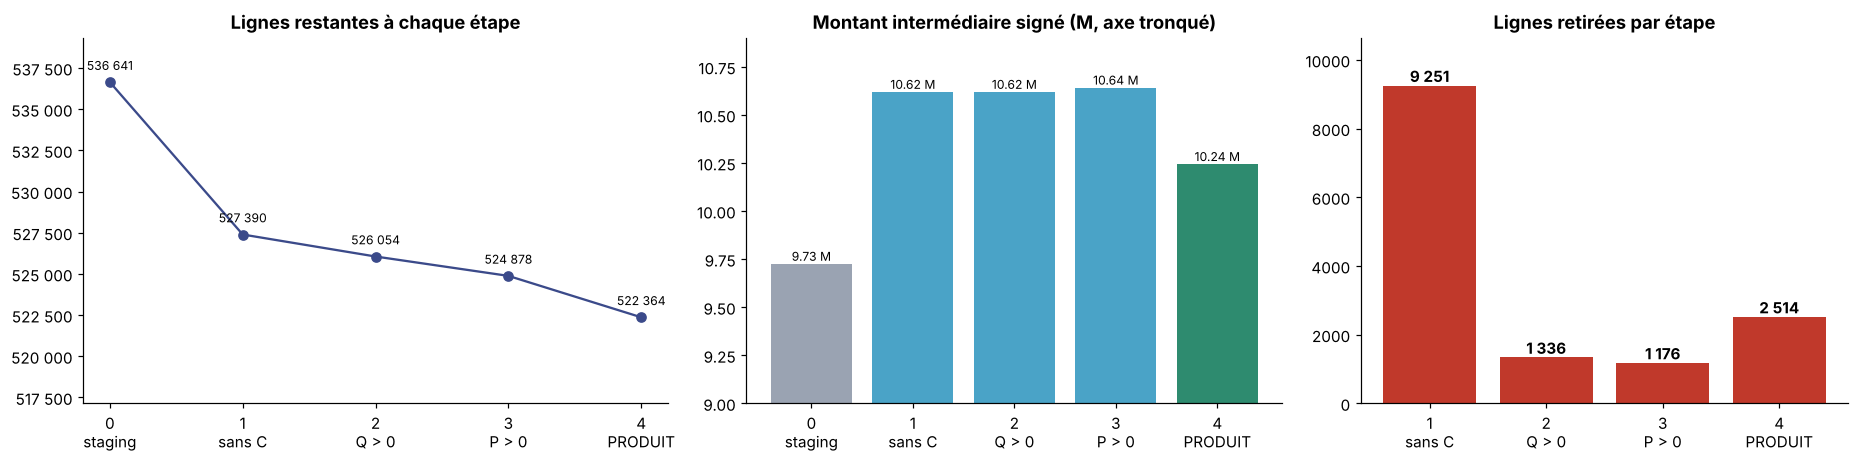

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3), gridspec_kw={'width_ratios': [1.2, 1.1, 1]})
lab = ['0\nstaging', '1\nsans C', '2\nQ > 0', '3\nP > 0', '4\nPRODUIT']
axes[0].plot(lab, journal['Restantes'], marker='o', color=C_PRIM)
for i, v in enumerate(journal['Restantes']):
    axes[0].annotate(fr(v), (i, v), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8)
axes[0].set_title('Lignes restantes à chaque étape'); axes[0].set_ylim(journal['Restantes'].min() * 0.99, journal['Restantes'].max() * 1.005)
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: fr(v)))

axes[1].bar(lab, journal['Montant'] / 1e6, color=[C_GRIS] + [C_BLEU] * 3 + [C_VERT])
for i, v in enumerate(journal['Montant'] / 1e6):
    axes[1].text(i, v, f'{v:.2f} M', ha='center', va='bottom', fontsize=8)
axes[1].set_ylim(9, 10.9); axes[1].set_title('Montant intermédiaire signé (M, axe tronqué)')

axes[2].bar(lab[1:], journal['Retirees'][1:], color=C_ROUGE)
for i, v in enumerate(journal['Retirees'][1:]):
    axes[2].text(i, v, fr(v), ha='center', va='bottom', fontweight='bold')
axes[2].set_ylim(0, journal['Retirees'].max() * 1.15); axes[2].set_title('Lignes retirées par étape')
plt.tight_layout(); plt.show()

**Lecture.** Le montant **n'est pas monotone** : il monte aux étapes 1 et 3 (on enlève des lignes négatives) puis redescend à l'étape 4 (on enlève des frais positifs). C'est pour cela que **comparer uniquement le montant final est insuffisant** : il faut comparer le journal étape par étape.

---
## PHASE 08 · Contrôle final : effectifs, provenances et montants
### Objectif
Prouver que le traitement est **cohérent** : aucune vente perdue ni ajoutée, aucun client absent perdu, aucune ligne dans deux blocs à la fois, réconciliation exacte des lignes et des montants.

### Explication du code
- `attendues` : on **recalcule indépendamment** l'ensemble des ventes admissibles depuis `integration` (mêmes conditions que le filtrage, écrites autrement). `ids_attendus` / `ids_observes` / `ids_clients_absents` : ensembles de `SourceIndex` (comparaison des **observations elles-mêmes**, indépendamment de l'ordre).
- Les `assert` vérifient : `SourceIndex` unique dans `preparee` ; ventes attendues = ventes observées ; ventes à client absent **toutes conservées** ; `preparee` ∩ `audit_exclusions` = ∅ ; `integration` = `preparee` ∪ `audit_exclusions` ; **`brut = doublons_exacts + audit_exclusions + preparee`**.
- `controle_lignes` : fusion ligne par ligne (`merge(..., how="outer", validate="one_to_one", indicator=True)`) pour vérifier que `MontantLigne = Quantity_num × UnitPrice_num` **sur chaque ligne**, puis que la somme totale concorde (`np.allclose`/`np.isclose` avec tolérance : pas une précision financière contractuelle).
- `controle_final` : le tableau à reporter. Le total est affiché à deux décimales **sans arrondi préalable** à chaque ligne.

In [15]:
attendues = integration.loc[
    (~integration["Annulation"])
    & (integration["Quantity_num"] > 0)
    & (integration["UnitPrice_num"] > 0)
    & integration["TypeLigne"].eq("PRODUIT_COMMERCIAL")
]
ids_attendus = set(attendues["SourceIndex"])
ids_observes = set(preparee["SourceIndex"])
ids_clients_absents = set(attendues.loc[attendues["CustomerID_norm"].isna(), "SourceIndex"])
assert preparee["SourceIndex"].is_unique
assert ids_observes == ids_attendus, "Ventes perdues ou ajoutées."
assert ids_clients_absents <= ids_observes, "Vente au client absent perdue."
assert set(preparee["SourceIndex"]).isdisjoint(set(audit_exclusions["SourceIndex"]))
assert set(integration["SourceIndex"]) == ids_observes | set(audit_exclusions["SourceIndex"])
assert len(brut) == len(doublons_exacts) + len(audit_exclusions) + len(preparee)
# Comparaison ligne par ligne ; une tolérance ne fixe pas une précision financière contractuelle.
controle_lignes = attendues[["SourceIndex", "Quantity_num", "UnitPrice_num"]].merge(
    preparee[["SourceIndex", "MontantLigne"]], on="SourceIndex", how="outer", validate="one_to_one", indicator=True
)
assert controle_lignes["_merge"].eq("both").all()
assert np.allclose(
    controle_lignes["Quantity_num"] * controle_lignes["UnitPrice_num"],
    controle_lignes["MontantLigne"], rtol=1e-12, atol=1e-9
)
assert np.isclose(montant(attendues), preparee["MontantLigne"].sum(), rtol=1e-12, atol=1e-9)
controle_final = pd.DataFrame({
    "Controle": ["Ventes préparées", "Lignes écartées après dédoublonnage",
                 "Quantité totale conservée", "Somme MontantLigne",
                 "Ventes conservées avec CustomerID manquant"],
    "Valeur_observee": [len(preparee), len(audit_exclusions),
                        preparee["Quantity_num"].sum(), preparee["MontantLigne"].sum(),
                        preparee["CustomerID_norm"].isna().sum()]
})
print(controle_final.to_string(index=False, float_format=lambda x: f"{x:.2f}"))
print("Provenances et montants : contrôles exécutés sans échec.")

                                  Controle  Valeur_observee
                          Ventes préparées        522364.00
       Lignes écartées après dédoublonnage         14277.00
                 Quantité totale conservée       5561117.00
                        Somme MontantLigne      10244661.18
Ventes conservées avec CustomerID manquant        131355.00
Provenances et montants : contrôles exécutés sans échec.


### Observation — contrôle final rempli
| Contrôle final | Valeur observée | Preuve / statut |
|---|---|---|
| Ventes préparées | **522 364** | ✅ `ids_observes == ids_attendus` |
| Lignes écartées après dédoublonnage | **14 277** | ✅ `integration = preparee ∪ audit_exclusions`, intersection vide |
| Quantité totale conservée | **5 561 117** | ✅ identique à la ligne finale du journal |
| Somme de MontantLigne (2 décimales) | **10 244 661,18** | ✅ `np.isclose(montant(attendues), Σ MontantLigne)` et contrôle ligne par ligne |
| Ventes conservées avec CustomerID manquant | **131 355** | ✅ `ids_clients_absents ⊆ ids_observes` |
| Provenances conservées sans perte ni duplication | tous les `SourceIndex` retrouvés une seule fois | ✅ `SourceIndex` unique ; `preparee` ∩ `audit_exclusions` = ∅ |
| Réconciliation brut = copies + exclusions + préparées | **541 909 = 5 268 + 14 277 + 522 364** | ✅ `assert` réussi |

**Interprétation.** Tous les contrôles passent sans échec. Les **131 355 ventes sans client** (25,1 % des ventes préparées) sont **conservées** : l'absence de `CustomerID` n'est pas un motif d'exclusion. **Limite à rappeler** : un contrôle cohérent ne prouve pas à lui seul que le référentiel métier soit exhaustif ; les règles et les cas non résolus (ex. `CARRIAGE`) sont à documenter, et le montant n'est pas un CA comptable net.

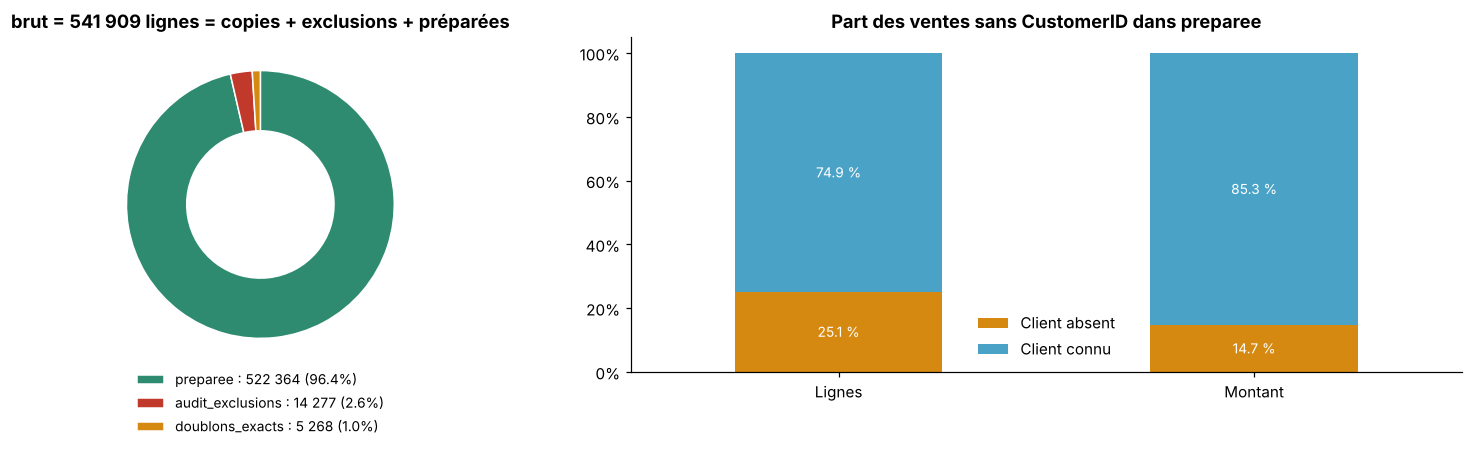

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
parts = [len(preparee), len(audit_exclusions), len(doublons_exacts)]
noms = ['preparee', 'audit_exclusions', 'doublons_exacts']
w, _ = axes[0].pie(parts, colors=[C_VERT, C_ROUGE, C_ORANGE], startangle=90, counterclock=False,
                   wedgeprops=dict(width=0.45, edgecolor='white'))
axes[0].legend(w, [f'{n} : {fr(v)} ({v/sum(parts):.1%})' for n, v in zip(noms, parts)],
               loc='upper center', bbox_to_anchor=(0.5, 0.04), frameon=False, fontsize=9)
axes[0].set_title(f'brut = {fr(len(brut))} lignes = copies + exclusions + préparées')

conn = preparee['CustomerID_norm'].notna()
cmp_ = pd.DataFrame({'Lignes': preparee.groupby(conn).size(), 'Montant': preparee.groupby(conn)['MontantLigne'].sum()})
cmp_ = cmp_ / cmp_.sum() * 100
cmp_.index = ['Client absent' if not i else 'Client connu' for i in cmp_.index]
cmp_.T.plot(kind='bar', stacked=True, ax=axes[1], color=[C_ORANGE, C_BLEU], rot=0)
for cont in axes[1].containers:
    axes[1].bar_label(cont, labels=[f'{v:.1f} %' for v in cont.datavalues], label_type='center', fontsize=9, color='white')
axes[1].set_title('Part des ventes sans CustomerID dans preparee'); axes[1].legend(frameon=False)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
plt.tight_layout(); plt.show()

**Lecture.** À gauche, les trois blocs reconstituent exactement le brut (aucune ligne perdue). À droite, les ventes **sans client** représentent environ un quart des lignes mais une part nettement plus faible du montant : les supprimer fausserait fortement l'analyse, d'où leur conservation.

---
## PHASE 09 · Exporter L2 dans Kaggle
### Objectif
Écrire les livrables dans `/kaggle/working` (téléchargeables dans les sorties du notebook), avec les pièces de traçabilité et le rapport HTML.

### Explication du code
- `to_csv(..., index=False, encoding="utf-8-sig")` : écrit chaque DataFrame en CSV sans l'index pandas, avec un encodage lisible par Excel (accents).
- `TP2_L2_SOURCE_PREPAREE.csv` = `preparee` ; `TP2_L2_STAGING_TRACE.csv` = `integration` (toutes les lignes uniques, typées, classifiées, tracées) ; `TP2_L2_AUDIT_EXCLUSIONS.csv` = `audit_exclusions` ; `TP2_L2_DOUBLONS_EXACTS.csv` ; `TP2_L2_JOURNAL_CONTROLES.csv`.
- `rapport` : construit une page HTML avec le fichier, son SHA-256, les tableaux calculés (`to_html`) et des **zones de commentaire** (`<textarea>`) à remplir ; `html.escape` protège le nom du fichier.
- La boucle finale liste les fichiers `TP2_*.csv` créés.
- Le nom `TP2_CORRECTION_IDEALE_M115.html` **ne fait pas** de ce rapport un corrigé de l'enseignante : c'est **votre** rapport commenté.

In [17]:
preparee.to_csv(sortie / "TP2_L2_SOURCE_PREPAREE.csv", index=False, encoding="utf-8-sig")
integration.to_csv(sortie / "TP2_L2_STAGING_TRACE.csv", index=False, encoding="utf-8-sig")
audit_exclusions.to_csv(sortie / "TP2_L2_AUDIT_EXCLUSIONS.csv", index=False, encoding="utf-8-sig")
# Pièces de traçabilité complémentaires.
doublons_exacts.to_csv(sortie / "TP2_L2_DOUBLONS_EXACTS.csv", index=False, encoding="utf-8-sig")
journal.to_csv(sortie / "TP2_L2_JOURNAL_CONTROLES.csv", index=False, encoding="utf-8-sig")
rapport = """<!doctype html><html lang="fr"><meta charset="utf-8">
<title>M115 — Rapport qualité L2</title><style>body{font-family:Arial;max-width:1100px;margin:30px auto;line-height:1.5}table{border-collapse:collapse}td,th{border:1px solid #ccc;padding:8px}textarea{width:95%;min-height:80px}@media print{textarea{border:1px solid #999}}</style>
<h1>M115 — TP2 · Rapport qualité L2</h1>
<p>Pr. AMINA ABOULMIRA · Étudiants : ______________________</p>"""
rapport += "<p>Fichier : " + html.escape(source.name) + "<br>SHA-256 : " + empreinte + "</p>"
for titre, tableau in [("Audit initial", audit_initial), ("Classification", classification_effectifs),
                       ("Journal des étapes", journal), ("Contrôle final", controle_final)]:
    rapport += "<h2>" + titre + "</h2>" + tableau.to_html(index=False, float_format=lambda x: f"{x:.2f}")
    rapport += '<p>Interprétation et anomalie éventuelle :</p><textarea></textarea>'
rapport += '<h2>Règles et preuves</h2><p>Joindre le script, commenter les copies exactes, le client absent et les motifs multiples. Le montant décrit le périmètre MVP, pas un CA comptable net.</p><p>Les graphiques sont facultatifs : les tableaux exacts restent prioritaires.</p><p>Pour conserver vos commentaires : imprimer ce rapport en PDF après saisie.</p></html>'
(sortie / "TP2_CORRECTION_IDEALE_M115.html").write_text(rapport, encoding="utf-8")
for nom in sorted(sortie.glob("TP2_*.csv")):
    print(nom.name)
print("TP2_CORRECTION_IDEALE_M115.html")
print("À joindre : TP2_L2_SCRIPT_REPRODUCTIBLE.py téléchargé depuis la fiche, et votre notebook exécuté.")

TP2_L2_AUDIT_EXCLUSIONS.csv
TP2_L2_DOUBLONS_EXACTS.csv
TP2_L2_JOURNAL_CONTROLES.csv
TP2_L2_SOURCE_PREPAREE.csv
TP2_L2_STAGING_TRACE.csv
TP2_CORRECTION_IDEALE_M115.html
À joindre : TP2_L2_SCRIPT_REPRODUCTIBLE.py téléchargé depuis la fiche, et votre notebook exécuté.


### Livrable L2 — pièces à remettre
| Fichier | Rôle |
|---|---|
| `TP2_L2_SOURCE_PREPAREE.csv` | 522 364 ventes éligibles, `MontantLigne`, `SourceIndex`, champs originaux et colonnes dérivées |
| `TP2_L2_STAGING_TRACE.csv` | 536 641 lignes uniques, typées, classifiées et tracées |
| `TP2_L2_AUDIT_EXCLUSIONS.csv` | 14 277 lignes uniques non éligibles, avec motifs et provenance |
| `TP2_L2_DOUBLONS_EXACTS.csv` | 5 268 copies retirées (traçabilité) |
| `TP2_L2_JOURNAL_CONTROLES.csv` | le journal des 5 étapes |
| `TP2_CORRECTION_IDEALE_M115.html` | rapport avec tableaux calculés et zones de commentaire (à imprimer en PDF après saisie) |
| `TP2_L2_SCRIPT_REPRODUCTIBLE.py` | script de la fiche, à joindre avec le notebook exécuté |

**Avant de commencer TP3** : le CSV préparé contient les huit champs originaux, `SourceIndex` et `MontantLigne` ✔ · le client absent est conservé, aucun membre de dimension n'a été créé ✔ · `InvoiceNo` reste un identifiant, aucune `DimCommande` n'est construite ✔ · aucune catégorie ni marque absente de la source n'a été inventée ✔ · la source préparée a été contrôlée et les cas non résolus sont documentés (`CARRIAGE`, voir phase 05) ✔.
**Pour poursuivre en TP3** : relire le CSV avec `InvoiceNo`, `StockCode` et `CustomerID` en type **texte** (`dtype=str`) ; convertir `InvoiceDate` explicitement ; `SourceIndex` reste un entier ; les calculs utilisent `Quantity_num` et `UnitPrice_num` ; aucun client absent n'est remplacé par un `CustomerID` égal à zéro.

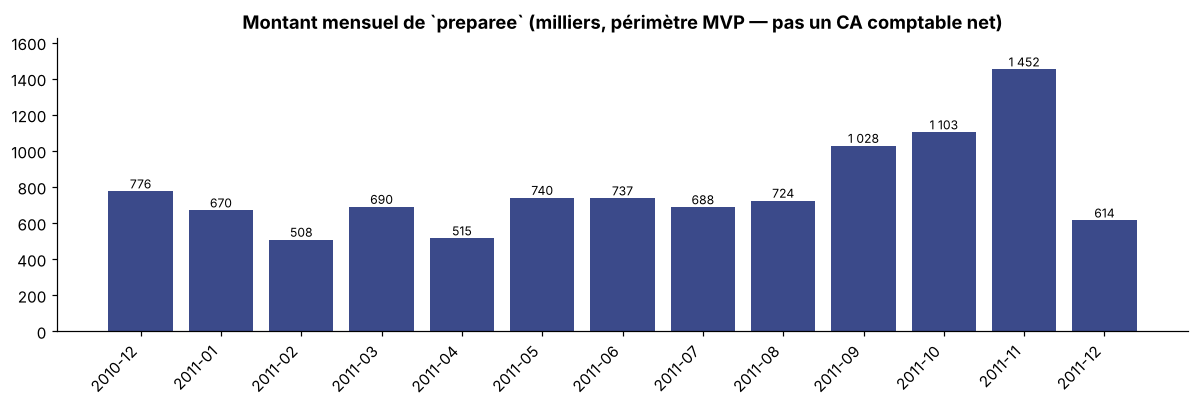

In [18]:
# Graphe facultatif : chiffre d'affaires mensuel du périmètre MVP (preparee)
mois = preparee.groupby(preparee['InvoiceDate_dt'].dt.to_period('M'))['MontantLigne'].sum()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(mois.index.astype(str), mois.values / 1e3, color=C_PRIM)
for i, v in enumerate(mois.values / 1e3):
    ax.text(i, v, f'{v:,.0f}'.replace(',', ' '), ha='center', va='bottom', fontsize=8)
ax.set_title("Montant mensuel de `preparee` (milliers, périmètre MVP — pas un CA comptable net)")
plt.setp(ax.get_xticklabels(), rotation=45, ha='right'); ax.set_ylim(0, mois.max() / 1e3 * 1.12)
plt.tight_layout(); plt.show()

**Lecture.** Saisonnalité nette avec un pic en **novembre 2011** ; décembre 2011 est **incomplet** (les données s'arrêtent au 9 décembre 2011). Ce graphe est facultatif : les tableaux exacts restent prioritaires.

---
## Quand deux montants finaux diffèrent : retrouver la première divergence
| Première différence observée | Ce qu'il faut examiner |
|---|---|
| Dès le brut | Fichier, empreinte, feuille chargée, huit colonnes |
| Après dédoublonnage | Huit colonnes originales ; métadonnées exclues ; `keep="first"` ; aucune normalisation préalable |
| Après classification | Dictionnaire complet ; codes normalisés ; descriptions suspectes ; `A_VERIFIER` |
| Après filtre annulation | Même convention `InvoiceNo` et même ordre |
| Après quantité ou prix | Types numériques ; `> 0` et non `>= 0` ; absence de filtre caché |
| Après type commercial | Même `TypeLigne` ; aucun filtre excluant les codes alphanumériques |
| Même effectif mais montant différent | Comparer `SourceIndex`, quantités, prix et `MontantLigne` ; chercher une perte compensée par une autre ligne |
| Client absent perdu | Rechercher `dropna(CustomerID)`, filtre `notna()` ou jointure incorrecte |

### Diagnostic à documenter
| Diagnostic | Votre relevé |
|---|---|
| Première étape divergente | **Aucune divergence constatée dans ce notebook** : tous les `assert` des phases 01 à 08 passent. À remplir avec votre binôme si vos chiffres diffèrent des valeurs de référence ci-dessous. |
| SourceIndex concernés | Sans objet (aucune divergence). Méthode : comparer les ensembles `SourceIndex` de `preparee` entre deux binômes (`set(a) ^ set(b)`). |
| Cause identifiée | Sans objet. Causes fréquentes : fichier/empreinte différents, `dropna()` global, `>= 0` au lieu de `> 0`, dictionnaire de classification modifié. |
| Correction réalisée et contrôle rejoué | Sans objet. Relancer *Run All* après toute correction et revérifier la cellule ci-dessous. |

> Ne jamais ajouter de filtre pour **forcer** un montant à correspondre.

In [19]:
# Valeurs de référence : comparez-les avec VOS résultats (affichage seulement, aucune interruption du notebook)
reference = {
    "SHA-256 du fichier":                    (empreinte, "43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d"),
    "Lignes brutes":                         (len(brut), 541909),
    "Copies exactes retirées":               (len(doublons_exacts), 5268),
    "Lignes uniques":                        (len(staging_unique), 536641),
    "A_VERIFIER":                            (int((integration['TypeLigne'] == 'A_VERIFIER').sum()), 207),
    "Étape 1 restantes":                     (len(etape_1), 527390),
    "Étape 2 restantes":                     (len(etape_2), 526054),
    "Étape 3 restantes":                     (len(etape_3), 524878),
    "Ventes préparées (étape 4)":            (len(preparee), 522364),
    "Lignes écartées (audit_exclusions)":    (len(audit_exclusions), 14277),
    "Quantité totale conservée":             (int(preparee['Quantity_num'].sum()), 5561117),
    "Somme MontantLigne (2 déc.)":           (round(float(preparee['MontantLigne'].sum()), 2), 10244661.18),
    "Ventes sans CustomerID":                (int(preparee['CustomerID_norm'].isna().sum()), 131355),
}
tab = pd.DataFrame([{"Indicateur": k, "Votre valeur": v[0], "Valeur de référence": v[1],
                     "Statut": "OK" if v[0] == v[1] else "DIFFÉRENT"} for k, v in reference.items()])
print(tab.to_string(index=False))
if (tab["Statut"] == "DIFFÉRENT").any():
    print("\n→ Au moins une valeur diffère : chercher la PREMIÈRE ligne DIFFÉRENT (de haut en bas) ; si c'est le SHA-256, le fichier n'est pas la même version.")
else:
    print("\n✔ Toutes les valeurs coïncident avec les valeurs de référence.")

                        Indicateur                                                     Votre valeur                                              Valeur de référence Statut
                SHA-256 du fichier 43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d 43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d     OK
                     Lignes brutes                                                           541909                                                           541909     OK
           Copies exactes retirées                                                             5268                                                             5268     OK
                    Lignes uniques                                                           536641                                                           536641     OK
                        A_VERIFIER                                                              207                                         

---
## Synthèse
| | |
|---|---|
| Source brute | 541 909 lignes × 8 colonnes (SHA-256 `43465a06…6424676d`) |
| Copies exactes retirées (tracées) | 5 268 |
| Lignes uniques | 536 641 |
| Lignes exclues, conservées dans `audit_exclusions` | 14 277 |
| **`preparee` (L2)** | **522 364 ventes**, quantité 5 561 117, `MontantLigne` = **10 244 661,18** |
| Ventes sans `CustomerID` conservées | 131 355 |
| Cas non résolu à signaler | `CARRIAGE` : de vrais produits classés `A_VERIFIER` |

**Réponse à la question de départ.** On obtient une source fiable en **observant avant de supprimer**, en retirant **uniquement** les copies exactes, en **classant** puis en **traçant chaque motif d'exclusion** (sans jamais les additionner deux fois), en conservant les ventes sans client, et en **prouvant** chaque étape par un journal, des ensembles de `SourceIndex` et une réconciliation exacte des lignes et des montants.